In [37]:
from src.train import model1
from src.train import model2
from src import config
from src.train import utils
from src.data_prep import CargadorDatos

## Modelo Regresion

In [2]:
cargador_modelo1 = CargadorDatos(config.DATA_PROCESSED / "train.csv", config.DATA_PROCESSED / "test.csv")
X_train, y_train, X_test, y_test = cargador_modelo1.obtener_datos()

In [3]:
modeloregresiondemanda = model1.ModeloRegresionDemanda(X_train, y_train, 3, 0.1,128,200)

In [4]:
modeloregresiondemanda.creacion_modelo()

In [5]:
resultado = modeloregresiondemanda.entrenamiento_modelo()

Epoch 1/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 59410.5508 - val_loss: 27887.5371
Epoch 2/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 16956.1621 - val_loss: 10400.1846
Epoch 3/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 7761.1079 - val_loss: 5851.8340
Epoch 4/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 6114.0718 - val_loss: 5275.9912
Epoch 5/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5802.4336 - val_loss: 5026.4902
Epoch 6/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5624.9028 - val_loss: 4851.6270
Epoch 7/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5409.1309 - val_loss: 4714.1387
Epoch 8/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5490.0049 - val_loss: 4583.3052
Epoch 9/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5109.5405 - val_loss: 4485.9038
Epoch 10/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5008.2896 - val_loss: 4295.0645
Epoch 11/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 4855.7861 - val_loss: 41

In [6]:
perdidas_modelo1 = utils.EvaluacionPerdidasRegresion(resultado)

In [7]:
perdidas_modelo1.perdidas()

,loss,val_loss
0,59410.550781,27887.537109
1,16956.162109,10400.184570
2,7761.107910,5851.833984
3,6114.071777,5275.991211
4,5802.433594,5026.490234
...,...,...
195,3270.338867,3030.924072
196,3259.371338,3029.559570
197,3257.671387,3001.592773
198,3268.088379,3104.331543


<Axes: >

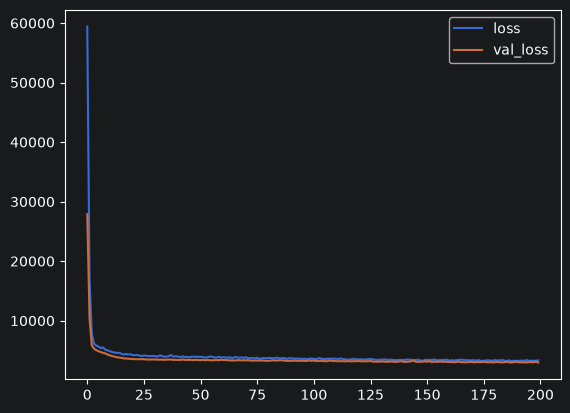

In [8]:
perdidas_modelo1.grafica_perdidas()

In [9]:
predicciones_modelo1 = modeloregresiondemanda.predecir(X_test)

109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step   


In [10]:
metricas_modelo1 = utils.Metricas(y_test, predicciones_modelo1)

In [11]:
metricas_modelo1.mae()

32.75406265258789

In [12]:
metricas_modelo1.diferecia_porc_mae()

,cnt
0,0.077068
1,0.372205
2,8.188516
3,0.062270
4,2.519543
...,...
3471,1.926710
3472,0.385342
3473,0.334225
3474,0.123136


In [13]:
metricas_modelo1.mrse()

np.float64(53.801653505462774)

In [14]:
metricas_modelo1.diferencia_porc_mrse()

,cnt
0,0.126592
1,0.611382
2,13.450413
3,0.102285
4,4.138589
...,...
3471,3.164803
3472,0.632961
3473,0.548996
3474,0.202262


In [15]:
metricas_modelo1.varianza_explicada()

0.908607542514801

In [16]:
metricas_modelo1.r2()

0.9085873961448669

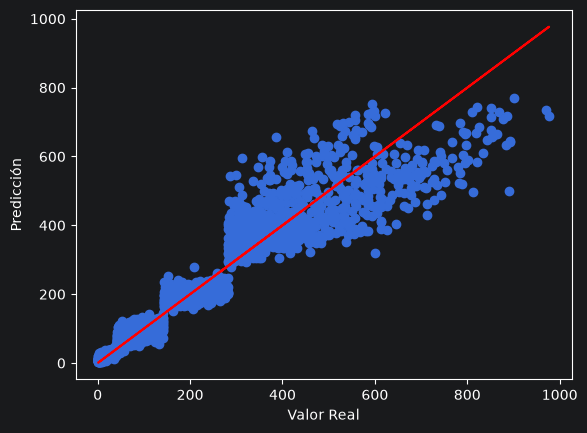

In [17]:
metricas_modelo1.grafico_valorreal_prediccion()

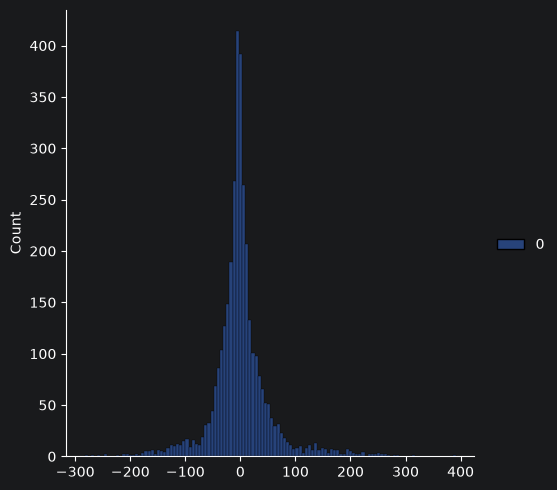

In [18]:
metricas_modelo1.grafico_error()

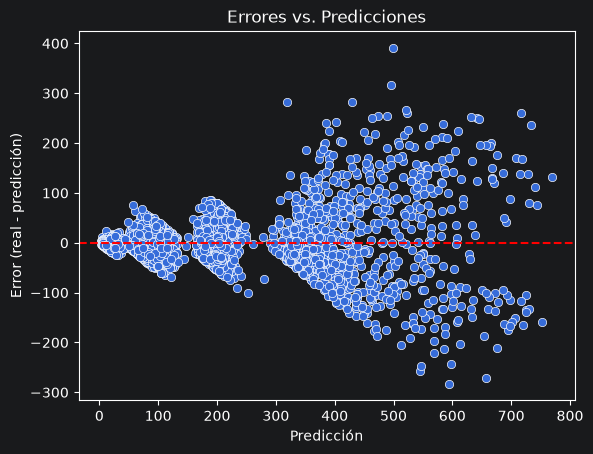

In [19]:
metricas_modelo1.grafico_errores_predicciones()

In [20]:
modeloregresiondemanda.guardar_modelo()

# Modelo Clasificacion

In [21]:
cargador_modelo2 = CargadorDatos(config.DATA_PROCESSED / "train.csv", config.DATA_PROCESSED / "test.csv", columna_objetivo="nivel_demanda",
        columnas_excluir=['cnt'])
X_train, y_train, X_test, y_test = cargador_modelo2.obtener_datos()

In [22]:
modeloclasificaciondemanda = model2.ModeloClasificacionDemanda(X_train, y_train, 3, 0.1, 128, 200)

In [23]:
modeloclasificaciondemanda.creacion_modelo()

<Sequential name=sequential_1, built=True>

In [24]:
resultado_clasificacion = modeloclasificaciondemanda.entrenamiento_modelo(X_train, y_train, X_test, y_test)

Epoch 1/200
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.4474 - loss: 1.2050 - val_accuracy: 0.6456 - val_loss: 0.8390
Epoch 2/200
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6396 - loss: 0.8197 - val_accuracy: 0.6985 - val_loss: 0.6962
Epoch 3/200
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6868 - loss: 0.7190 - val_accuracy: 0.7376 - val_loss: 0.6214
Epoch 4/200
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7146 - loss: 0.6574 - val_accuracy: 0.7402 - val_loss: 0.5886
Epoch 5/200
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7247 - loss: 0.6273 - val_accuracy: 0.7514 - val_loss: 0.5654
Epoch 6/200
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7357 - loss: 0.6028 - val_accuracy: 0.7555 - val_loss: 0.5570
Epoch 7/200
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7418 - loss: 0.5930 - val_accuracy: 0.7526 - val_loss: 0.5506
Epoch 8/200
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7424 - loss: 0.5847 - val_acc

In [25]:
perdidas_modelo2 = utils.EvaluacionPerdidasClasificacion(resultado_clasificacion)

In [26]:
perdidas_modelo2.perdidas()

,accuracy,loss,val_accuracy,val_loss
0,0.447385,1.204983,0.645570,0.839035
1,0.639574,0.819717,0.698504,0.696157
2,0.686830,0.719029,0.737629,0.621415
3,0.714594,0.657425,0.740219,0.588599
4,0.724664,0.627331,0.751438,0.565379
...,...,...,...,...
77,0.788751,0.468556,0.760932,0.513692
78,0.785010,0.469336,0.756041,0.517276
79,0.791340,0.463291,0.760069,0.517664
80,0.789326,0.463994,0.762371,0.515768


<Axes: >

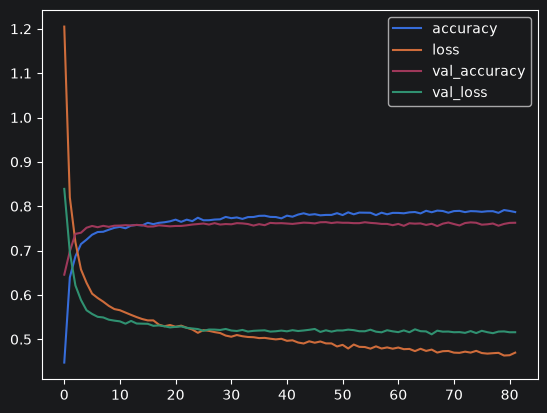

In [27]:
perdidas_modelo2.grafica_perdidas()

In [28]:
predicciones_prob = modeloclasificaciondemanda.predecir(X_test)

109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


In [29]:
predicciones_clase = predicciones_prob.argmax(axis=1)

In [30]:
metricas_modelo2 = utils.MetricasClasificacion(y_test, predicciones_clase)

In [31]:
metricas_modelo2.accurancy()

0.7626582278481012

In [32]:
metricas_modelo2.matriz_confusion()

array([[783,  65,   4,   0],
       [105, 629, 183,   9],
       [  0, 121, 621, 116],
       [  0,   7, 215, 618]])

In [33]:
metricas_modelo2.reporte_clasificacion()

'              precision    recall  f1-score   support\n\n           0       0.88      0.92      0.90       852\n           1       0.77      0.68      0.72       926\n           2       0.61      0.72      0.66       858\n           3       0.83      0.74      0.78       840\n\n    accuracy                           0.76      3476\n   macro avg       0.77      0.76      0.77      3476\nweighted avg       0.77      0.76      0.76      3476\n'

In [34]:
metricas_modelo2.matriz_confusion()

array([[783,  65,   4,   0],
       [105, 629, 183,   9],
       [  0, 121, 621, 116],
       [  0,   7, 215, 618]])

In [38]:
modeloregresiondemanda.guardar_modelo()